# Runge-Kutta de cuarto orden (RK4): suspensión masa-resorte-amortiguador

**Objetivo:** simular el modelo desde varias condiciones iniciales e interpretar
su evolución temporal y su retrato de fase.

Para el desplazamiento respecto al equilibrio estático:
$\dot x=v$, $\dot v=-(k/m)x-(c/m)v$. Usamos $m=250$ kg,
$k=15000$ N/m, $c=900$ N·s/m y sin excitación externa.
La condición principal parte de $x=0.25$ m y $v=0$.

RK4 combina cuatro pendientes por paso:
$k_1=f(t_k,x_k)$, $k_2=f(t_k+h/2,x_k+hk_1/2)$,
$k_3=f(t_k+h/2,x_k+hk_2/2)$ y $k_4=f(t_k+h,x_k+hk_3)$.
La actualización es $x_{k+1}=x_k+h(k_1+2k_2+2k_3+k_4)/6$.
La biblioteca implementa este método; la elección del paso debe verificarse
frente a una solución de referencia.

In [1]:
%matplotlib inline
import numpy as np
from sistemas_dinamicos import integrar, graficar, retrato_fase

m, k, c = 250.0, 15000.0, 900.0
def f(t, x):
    return np.array([x[1], -k/m*x[0]-c/m*x[1]])
equilibrio = (0, 0)
print("Amortiguamiento crítico:", 2*np.sqrt(k*m), "N·s/m")
h = 0.002
t = np.linspace(0, 4.0, round(4.0/h) + 1)
condiciones = [[0.25, 0], [-0.25, 0], [0, 2.2], [0, -2.2], [0.18, 1.5], [-0.18, -1.5]]
trayectorias = [integrar(f, t, x0, metodo="rk4") for x0 in condiciones]
principal = trayectorias[0]
print("Paso:", t[1]-t[0], "s; condición inicial:", condiciones[0])

Amortiguamiento crítico: 3872.983346207417 N·s/m
Paso: 0.002 s; condición inicial: [0.25, 0]


## Evolución temporal

La primera condición inicial es la trayectoria principal.

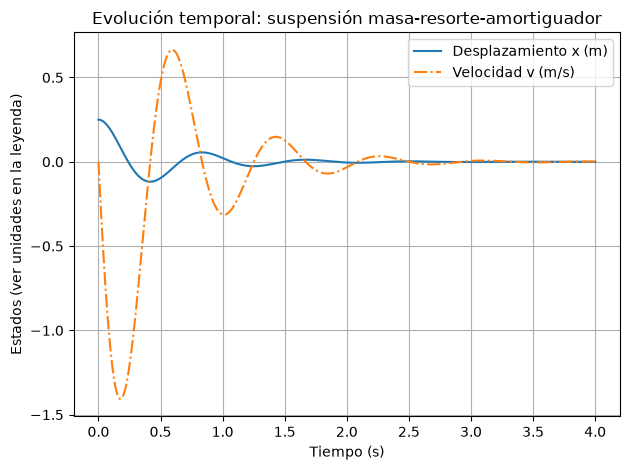

In [2]:
graficar(t, {"Desplazamiento x (m)": principal[:, 0], "Velocidad v (m/s)": principal[:, 1]},
         titulo="Evolución temporal: suspensión masa-resorte-amortiguador", ylabel="Estados (ver unidades en la leyenda)");

## Retrato de fase

Cada punto negro marca el inicio de una trayectoria.

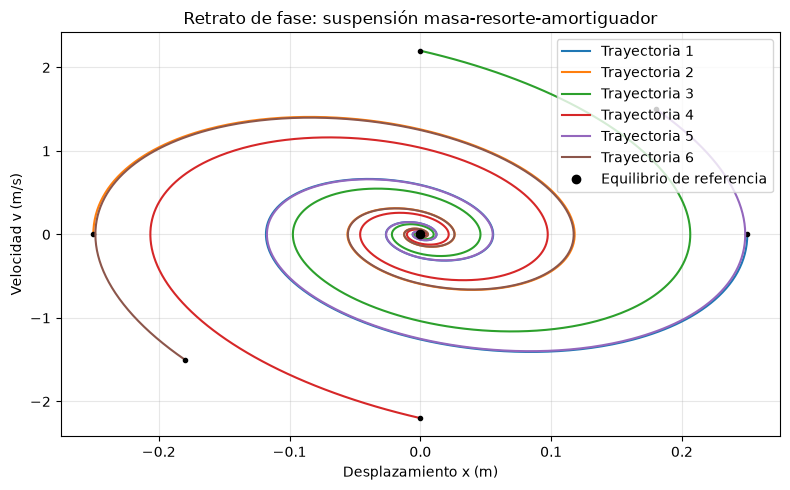

In [3]:
fig, ax = retrato_fase(trayectorias, titulo="Retrato de fase: suspensión masa-resorte-amortiguador",
                        xlabel="Desplazamiento x (m)", ylabel="Velocidad v (m/s)")
ax.plot(*equilibrio, "ko", label="Equilibrio de referencia")
ax.legend();

## Interpretación y práctica

El amortiguamiento es menor que el crítico: la respuesta oscila con
amplitud decreciente. Este valor de $c$ es distinto del usado en el cuaderno
del campo de fase.

**Practica:** reduce el paso a la mitad y compara la respuesta; luego prueba
el amortiguamiento crítico.